In [2]:
import sys, os, importlib, datetime

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Limit regimes of ice formation in turbulent supercooled water
#   @ https://arxiv.org/html/1607.08528v3#S8.E66
# Field measurements of Arctic grease ice properties and processes (Smedsrud et al. 2006)
#   @ https://www.sciencedirect.com/science/article/pii/S0165232X05001813

In [5]:
def gen_cores_linear(N=10, bins=32, T_top=-10.0, S_top=10.0, rho_top=0.8, thickness=0.5, cells_per_m=30, dtype=torch.float32, device="cuda"):
    """
    : Initialize grid-sampled experiments using a simple linear ice column model.
    T_top, S_top, rho_top, thickness :
        scalar        -> constant
        (min, max)    -> N-length linear sweep
    """
    T_b, S_b, rho_b = -1.8, 35.0, 1.028 # Fixed seawater values
    def expand(x):
        if isinstance(x, (tuple, list)): return torch.linspace(x[0], x[1], N, dtype=dtype, device=device)
        else: return torch.tensor([x], dtype=dtype, device=device)
    # initialize parameter tensor (4, nT, nS, nR, nH)
    params = torch.stack(torch.meshgrid(*[expand(var) for var in (T_top, S_top, rho_top, thickness)], indexing='ij'), dim=0)
    params[...,-1] = params[...,-1] * cells_per_m / bins # normalize thickness for profile coordinates
    span = (torch.linspace(0,1,bins,device=device).view(bins,1,1,1,1,1) / params[-1][None,None,]).clamp(0,1) # 0 is surface, 1 is bottom
    params = params[None,...].expand(bins,-1,-1,-1,-1,-1) # (bins, 4, nT, nS, nR, nH)
    params = (1 - span)*params + span*torch.tensor([T_b,S_b,rho_b,0], device=device).view(1,-1,1,1,1,1) # linear blend from top to bottom
    T, S, rho = params.moveaxis(0,-1).view(4,-1,bins)[:3] # (bins,4,...)->(4,...,bins)->(3,n,bins)->3x(n,bins)
    return T, S, rho
'''
CORE VARIABLE TESTS FOR EM-SIM
:
: all depth-wise change is MONOTONIC & LINEAR.
:
Practical bounds for T, S, rho
T  : -1.8 @ bottom, -30-0 @ top
S  : 35 @ bottom, 0-15 @ top
r  : 1.028 @ bottom, 0.5-1 @ top
th : 0 - 1 thickness
:
Baseline : variables will be based off on the standard scenario,
T  : -1.8 @ bottom, -10 @ top
S  : 35 @ bottom, 10 @ top
r  : 1 @ bottom, 0.8 @ top
th : 0.5 m
'''
#lincore_experiments = gen_cores_linear(8, bins=90, T_top=(-4, -18), S_top=(0,14), rho_top=(0.6,0.95), thickness=(0.1,1.5))
frazilmass_experiments = gen_cores_linear(16, bins=30, T_top=(-4, -20), S_top=(20,30), rho_top=(0.9,0.95), thickness=(0.05,0.5), cells_per_m=180)
#print([el.shape for el in lincore_experiments])

In [6]:
import data_resice; importlib.reload(data_resice)
import script_CoreExplorer; importlib.reload(script_CoreExplorer)
import brack2bing; importlib.reload(brack2bing)

select_option='simple'

# params
bins   = 90
hshape = (90, 90)
# ALOS-1 : 0.236m  -  Sentinel-1 : 0.0555m
wavelength_m = 0.0555
# ALOS-1 : 30 (3m @ 90c)  -  Sentinel-1 : 180 (0.5m @ 90c)
cells_per_m  = 180
# ALOS-1 : 8-60 deg QPOL  -  Sentinel-1 : 18-48 deg
ia_bounds    = (0,1)
input_cores = frazilmass_experiments
device = 'cuda'

def augment_func(T, S, rho, nums=100, L=(5, 90)):
    for v in (T, S, rho):
        vmin, vmax, vvar = v.amin(), v.amax(), v.var(dim=0)
        v = v[:,None].expand(-1,nums,-1).clone()
        for i in range(nums):
            vL = L[0] + ((L[1] - L[0]) * torch.rand(1)).to(v.device)
            v[:,i] = script_CoreExplorer.WienerNoiser(v[:,None,i], vvar, vL).clamp(vmin, vmax)[:,0]
        yield v.reshape(-1,v.shape[-1]) # collapse channel dim into batch dimension

match select_option:
    case 'resice':
        collector = script_CoreExplorer.generate_resice(fn='em_resice_261008_S1.hdf5',
            bins=bins, hshape=hshape, wavelength_m=wavelength_m, cells_per_m=cells_per_m, ia_b=ia_bounds,
            min_samples=5, get_oversize=True, device=device, augment_function=augment_func, lattice_freeboard_m=0.25
        )
    case 'randoms':
        collector = script_CoreExplorer.generate_randoms(
            iters=500, batch_n=12, # 6000 samples
            bins=bins, hshape=hshape, wavelength_m=wavelength_m, cells_per_m=cells_per_m, ia_b=ia_bounds,
            device=device
        )
    case 'simple':
        collector = script_CoreExplorer.generate_(input_cores, fn='em_gridlook_Cband_i0_261103.hdf5',
            batch_n=12, hshape=hshape, wavelength_m=wavelength_m, cells_per_m=cells_per_m, ia_b=ia_bounds,
            device=device
        )
try: collector.close()
except: pass

floquet incidence modes: [0.]


KeyboardInterrupt: 

In [16]:
#frazilmass_experiments[0].shape
import h5py
f = h5py.File('em_gridlook_Cband_i0_261103.hdf5', 'r')
T, S, rho, rf = f['T']['d'][:], f['S']['d'][:], f['rho']['d'][:], f['rf']['d'][:]


In [85]:
#icesim = brack2bing.LatticeSolver.load()
icefrac = icesim.cpu().get_icefrac(torch.as_tensor(T), torch.as_tensor(S))

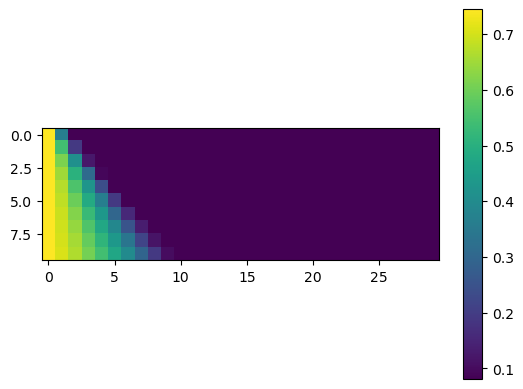

In [106]:
plt.imshow(icefrac[:10]); plt.colorbar()

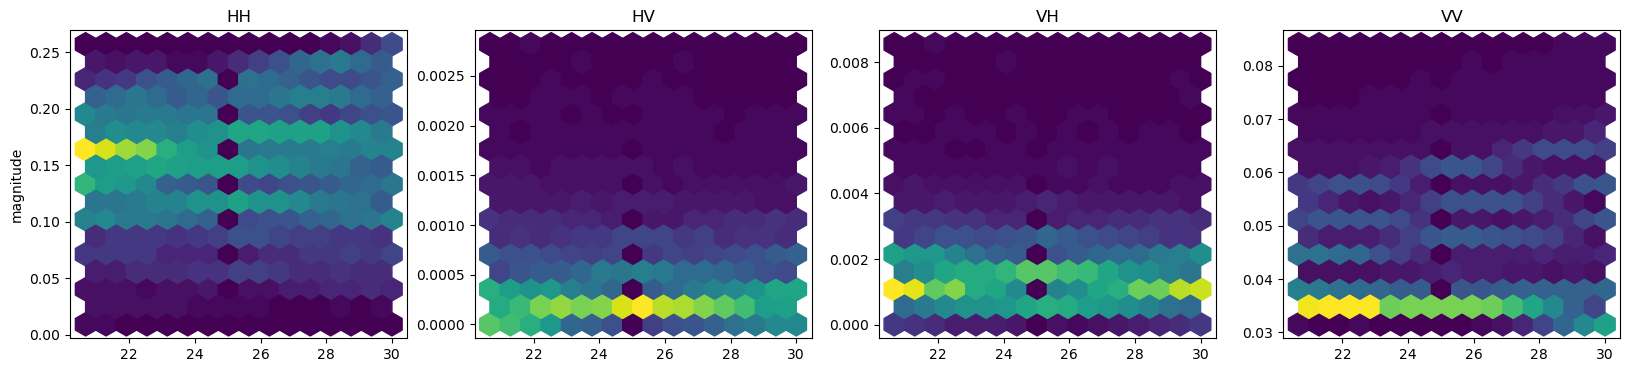

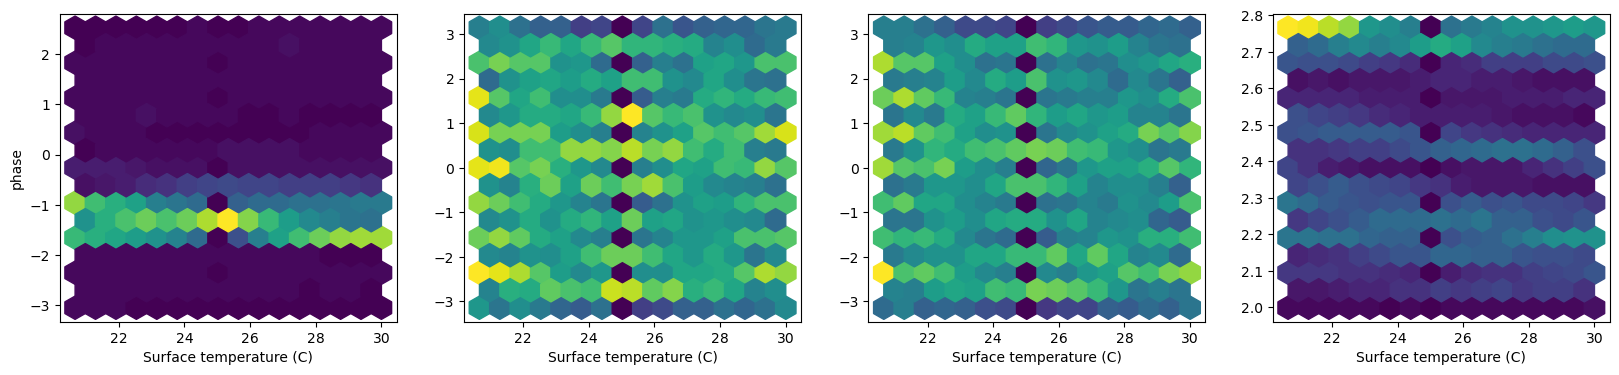

In [148]:
mask = (T[:,0] > -25) * (S[:,0] < 40) * (S[:,0] > 20)
scat = ['HH','HV','VH','VV']
var = S[mask]#T[mask]
plt.figure(figsize=(20,4))
for pol in range(4):
    plt.subplot(1,4,pol+1)
    if pol == 0 : plt.ylabel('magnitude')
    rf_look = np.abs(rf[mask][:,pol])
    plt.hexbin(var[:,0], rf_look, bins=50, gridsize=15)
    plt.title(scat[pol])
plt.show()
plt.figure(figsize=(20,4))
for pol in range(4):
    plt.subplot(1,4,pol+1)
    if pol == 0 : plt.ylabel('phase')
    rf_look = np.angle(rf[mask][:,pol])
    plt.hexbin(var[:,0], rf_look, bins=50, gridsize=15)
    plt.xlabel('Surface temperature (C)')
    #plt.title(scat[pol])



#plt.suptitle('Simulated scattering phase over DxLxW 30x90x30')
plt.show()

In [41]:
T.shape

(30000, 30)